# Homework 2: Factor Models and Performance Measurement
**bs3759** · Quantitative Methods in Investment Management

**How to run**
1. Keep `Performance_Measurement_Spreadsheet-1.xlsx` in the `data/` folder next to this notebook (in Colab, upload it to a `data` folder in the Files panel).
2. Run **Restart & Run All**. Every table and figure in the report is computed below from the spreadsheet; no result is typed in by hand.

The written answers and interpretation are in the PDF report.

In [1]:
# Only needed if a library is missing (uncomment and run once, then restart the kernel)
# %pip install numpy pandas matplotlib statsmodels openpyxl

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)

DATA_FILE = "data/Performance_Measurement_Spreadsheet-1.xlsx"

## Part II: Data audit and sensitivity analysis
### 3. Sample, frequency, missing values and units

In [3]:
df = pd.read_excel(DATA_FILE, header=2)            # column names are in row 3

df = df.rename(columns={df.columns[0]: "Date"})    # row 3 has no label above the dates
df = df.dropna(axis=1, how="all")                  # drop empty columns (B, D, I)
df = df.dropna(subset=["Date"])                    # drop any empty rows at the bottom
df.columns = df.columns.str.strip()                # remove stray spaces in names
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)

print(df.shape)
print(df.columns.tolist())

(222, 16)
['Date', 'RF', 'Mkt-RF', 'SMB', 'HML', 'UMD', 'Ln/Sh Eq Hedge Fund USD', 'Eq Mkt Ntr Hedge Fund USD', 'Ded Sh Bs Hedge Fund USD', 'Global Mac Hedge Fund USD', 'Mngd Fut Hedge Fund USD', 'Emg Mkts Hedge Fund USD', 'Evnt Drvn Hedge Fund USD', 'Cnvrt Arb Hedge Fund USD', 'Fx Inc Arb Hedge Fund USD', 'DJCS Hedge Fund USD']


In [4]:
print("Sample start:", df["Date"].min().date(), "| Sample end:", df["Date"].max().date())
print("Frequency:", pd.infer_freq(df["Date"]))      # BME = business month-end

Sample start: 1994-01-31 | Sample end: 2012-06-29
Frequency: BME


In [5]:
print("Missing values per column:")
print(df.isna().sum())

print("\nPlaceholder values (<= -99) per column:")
print((df.select_dtypes("number") <= -99).sum())

print("\nData types:")
print(df.dtypes)

Missing values per column:
Date                         0
RF                           0
Mkt-RF                       0
SMB                          0
HML                          0
UMD                          0
Ln/Sh Eq Hedge Fund USD      0
Eq Mkt Ntr Hedge Fund USD    0
Ded Sh Bs Hedge Fund USD     0
Global Mac Hedge Fund USD    0
Mngd Fut Hedge Fund USD      0
Emg Mkts Hedge Fund USD      0
Evnt Drvn Hedge Fund USD     0
Cnvrt Arb Hedge Fund USD     0
Fx Inc Arb Hedge Fund USD    0
DJCS Hedge Fund USD          0
dtype: int64

Placeholder values (<= -99) per column:
RF                           0
Mkt-RF                       0
SMB                          0
HML                          0
UMD                          0
Ln/Sh Eq Hedge Fund USD      0
Eq Mkt Ntr Hedge Fund USD    0
Ded Sh Bs Hedge Fund USD     0
Global Mac Hedge Fund USD    0
Mngd Fut Hedge Fund USD      0
Emg Mkts Hedge Fund USD      0
Evnt Drvn Hedge Fund USD     0
Cnvrt Arb Hedge Fund USD     0
Fx Inc Arb Hedge Fun

In [6]:
# Decimal-units check: monthly returns in decimals have mean |r| of a few percent and max well below 1
num_cols = df.select_dtypes(include=np.number).columns.tolist()
print(df[num_cols].abs().describe().loc[["mean", "max"]].T)

                               mean       max
RF                         0.002536  0.005600
Mkt-RF                     0.037558  0.185500
SMB                        0.025034  0.220600
HML                        0.023889  0.138800
UMD                        0.035495  0.347500
Ln/Sh Eq Hedge Fund USD    0.022121  0.129913
Eq Mkt Ntr Hedge Fund USD  0.011673  0.404590
Ded Sh Bs Hedge Fund USD   0.038824  0.226661
Global Mac Hedge Fund USD  0.020914  0.115652
Mngd Fut Hedge Fund USD    0.027038  0.099063
Emg Mkts Hedge Fund USD    0.031691  0.230716
Evnt Drvn Hedge Fund USD   0.015025  0.118201
Cnvrt Arb Hedge Fund USD   0.014614  0.126007
Fx Inc Arb Hedge Fund USD  0.010886  0.140442
DJCS Hedge Fund USD        0.016815  0.085117


In [7]:
usable = df.replace([np.inf, -np.inf], np.nan).dropna()

table1 = pd.DataFrame({
    "Item": ["Start date", "End date", "Frequency", "Total observations", "Usable observations"],
    "Value": [
        df["Date"].min().strftime("%Y-%m-%d"),
        df["Date"].max().strftime("%Y-%m-%d"),
        "Monthly (business month-end)",
        len(df),
        len(usable),
    ],
})

print("Table 1: Data audit")
print(table1.to_string(index=False))

Table 1: Data audit
               Item                        Value
         Start date                   1994-01-31
           End date                   2012-06-29
          Frequency Monthly (business month-end)
 Total observations                          222
Usable observations                          222


### 4. Equity Market Neutral: largest absolute monthly return

In [8]:
col = "Eq Mkt Ntr Hedge Fund USD"
idx = df[col].abs().idxmax()                       # row with the largest absolute return
print(df.loc[idx, ["Date", col]])

Date                         2008-11-28 00:00:00
Eq Mkt Ntr Hedge Fund USD               -0.40459
Name: 178, dtype: object


In [9]:
def emn_stats(R):
    T = len(R)
    G = (1 + R).prod() ** (1 / T) - 1                                      # geometric average (monthly)
    V = pd.concat([pd.Series([1.0]), (1 + R).cumprod()], ignore_index=True) # cumulative wealth, V0 = 1
    HWM = V.cummax()                                                        # high-water mark
    DD = 1 - V / HWM                                                        # drawdown
    return [G, DD.max(), R.skew(), R.kurt()]                                # kurt() is already excess kurtosis

R = df[col]
R_ex = R.drop(R.abs().idxmax()).reset_index(drop=True)                      # excluding the largest observation

table2 = pd.DataFrame({
    "Full sample": emn_stats(R),
    "Excl. largest obs.": emn_stats(R_ex),
}, index=["Geometric average (monthly)", "Maximum drawdown", "Skewness", "Excess kurtosis"])

print("Table 2: Equity Market Neutral - full sample vs. excluding largest observation")
print(table2.round(4))

Table 2: Equity Market Neutral - full sample vs. excluding largest observation
                             Full sample  Excl. largest obs.
Geometric average (monthly)       0.0038              0.0062
Maximum drawdown                  0.4513              0.0785
Skewness                        -11.8665             -0.9839
Excess kurtosis                 162.7604              5.1177


## Part III: Cross-strategy performance
### 5. Summary statistics for the nine strategy indexes

In [10]:
strategies = [c for c in df.columns if "Hedge Fund USD" in c and not c.startswith("DJCS")]

def short(names):
    return names.str.replace(" Hedge Fund USD", "").str.strip()

def summary(R, RF):
    T = len(R)
    E = R - RF                                       # monthly excess returns

    arith = 12 * R.mean()                            # annualized arithmetic average
    geo = (1 + R).prod() ** (12 / T) - 1             # annualized geometric return

    vol = E.std() * np.sqrt(12)                      # annualized volatility of excess returns
    sharpe = 12 * E.mean() / vol                     # annualized Sharpe ratio

    V = pd.concat([pd.Series([1.0]), (1 + R).cumprod()], ignore_index=True)
    mdd = (1 - V / V.cummax()).max()                 # maximum drawdown depth

    return {
        "Arith. ret": arith, "Geo. ret": geo, "Vol": vol, "Sharpe": sharpe,
        "MDD": mdd, "Skew": E.skew(), "Ex. kurt": E.kurt(),
    }

table3 = pd.DataFrame({s: summary(df[s], df["RF"]) for s in strategies}).T
table3.index = short(table3.index)

print("Table 3: Summary statistics of hedge fund strategy indexes")
print(table3.round(4))

Table 3: Summary statistics of hedge fund strategy indexes
            Arith. ret  Geo. ret     Vol  Sharpe     MDD     Skew  Ex. kurt
Ln/Sh Eq        0.0904    0.0889  0.0990  0.6058  0.2214  -0.0731    3.2026
Eq Mkt Ntr      0.0529    0.0468  0.1022  0.2201  0.4513 -11.9943  165.3335
Ded Sh Bs      -0.0266   -0.0401  0.1697 -0.3362  0.6424   0.6527    1.3126
Global Mac      0.1151    0.1163  0.0964  0.8783  0.2700  -0.0994    3.9010
Mngd Fut        0.0613    0.0559  0.1169  0.2639  0.1788   0.0246   -0.0259
Emg Mkts        0.0799    0.0708  0.1489  0.3319  0.4533  -0.8086    5.1433
Evnt Drvn       0.0883    0.0898  0.0629  0.9200  0.1930  -2.2441   11.3846
Cnvrt Arb       0.0735    0.0734  0.0690  0.6246  0.3300  -2.5672   15.8173
Fx Inc Arb      0.0524    0.0519  0.0573  0.3832  0.2910  -4.2300   29.3784


### 6. Performance relative to the DJCS Hedge Fund Index

In [11]:
bench = df["DJCS Hedge Fund USD"]

A = df[strategies].sub(bench, axis=0)              # monthly active returns, all 9 strategies

active = 12 * A.mean()                             # annualized active return
te = A.std() * np.sqrt(12)                         # annualized tracking error
ir = active / te                                   # annualized information ratio

table4 = pd.DataFrame({"Active return": active, "Tracking error": te, "Information ratio": ir})
table4.index = short(table4.index)

print("Table 4: Active performance relative to the DJCS Hedge Fund Index")
print(table4.round(4))

Table 4: Active performance relative to the DJCS Hedge Fund Index
            Active return  Tracking error  Information ratio
Ln/Sh Eq           0.0063          0.0557             0.1130
Eq Mkt Ntr        -0.0312          0.1077            -0.2899
Ded Sh Bs         -0.1107          0.2179            -0.5081
Global Mac         0.0310          0.0569             0.5448
Mngd Fut          -0.0228          0.1270            -0.1798
Emg Mkts          -0.0043          0.1089            -0.0391
Evnt Drvn          0.0042          0.0498             0.0843
Cnvrt Arb         -0.0106          0.0687            -0.1541
Fx Inc Arb        -0.0317          0.0657            -0.4835


### 7. Equity Long/Short, Global Macro and Convertible Arbitrage

In [12]:
three = ["Ln/Sh Eq", "Global Mac", "Cnvrt Arb"]
table5 = table3.loc[three, ["Arith. ret", "Geo. ret", "Sharpe", "MDD"]]

ranks = table5.rank(ascending=False)               # higher is better for returns and Sharpe
ranks["MDD"] = table5["MDD"].rank()                # lower is better for drawdown

print("Table 5: Comparison of Long/Short Equity, Global Macro and Convertible Arbitrage (rank in brackets)")
print(table5.round(4).astype(str) + " (" + ranks.astype(int).astype(str) + ")")

Table 5: Comparison of Long/Short Equity, Global Macro and Convertible Arbitrage (rank in brackets)
            Arith. ret    Geo. ret      Sharpe         MDD
Ln/Sh Eq    0.0904 (2)  0.0889 (2)  0.6058 (3)  0.2214 (1)
Global Mac  0.1151 (1)  0.1163 (1)  0.8783 (1)    0.27 (2)
Cnvrt Arb   0.0735 (3)  0.0734 (3)  0.6246 (2)    0.33 (3)


## Part IV: Path dependence and smoothing
### 8. Global Macro: cumulative wealth and drawdown

In [13]:
gm = df.set_index("Date")["Global Mac Hedge Fund USD"]

# Cumulative wealth starting at 100 (one month before the first return)
start = gm.index[0] - pd.offsets.BMonthEnd(1)
V_gm = pd.concat([pd.Series([100.0], index=[start]), 100 * (1 + gm).cumprod()])

HWM_gm = V_gm.cummax()
DD_gm = 1 - V_gm / HWM_gm

trough = DD_gm.idxmax()
depth = DD_gm.max()
peak = V_gm.loc[:trough].idxmax()                  # highest wealth before the trough
after = V_gm.loc[trough:]
recovered = after[after >= V_gm.loc[peak]]
recovery = recovered.index[0] if len(recovered) > 0 else None

print("Table 6: Global Macro - maximum drawdown")
print("Peak date:     ", peak.date(), f"(wealth {V_gm.loc[peak]:.2f})")
print("Trough date:   ", trough.date(), f"(wealth {V_gm.loc[trough]:.2f})")
print("Depth:         ", f"{depth:.2%}")
if recovery is not None:
    print("Recovery date: ", recovery.date())
    print("Months from peak to recovery:", len(V_gm.loc[peak:recovery]) - 1)
else:
    print("Recovery date:  not recovered within the sample")

Table 6: Global Macro - maximum drawdown
Peak date:      1998-07-31 (wealth 250.32)
Trough date:    1999-09-30 (wealth 182.73)
Depth:          27.00%
Recovery date:  2001-03-30
Months from peak to recovery: 32


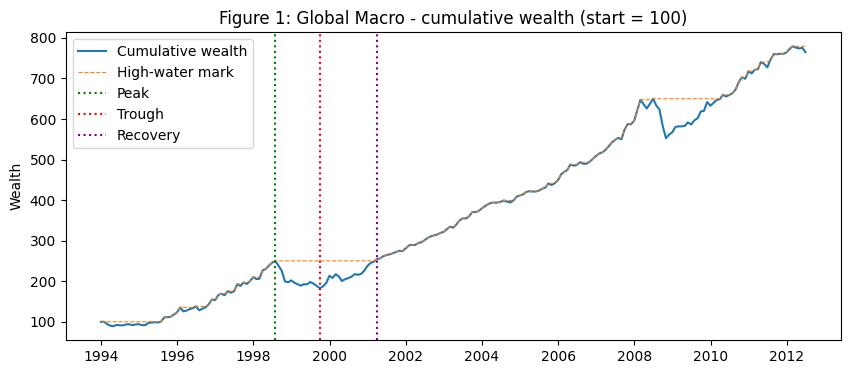

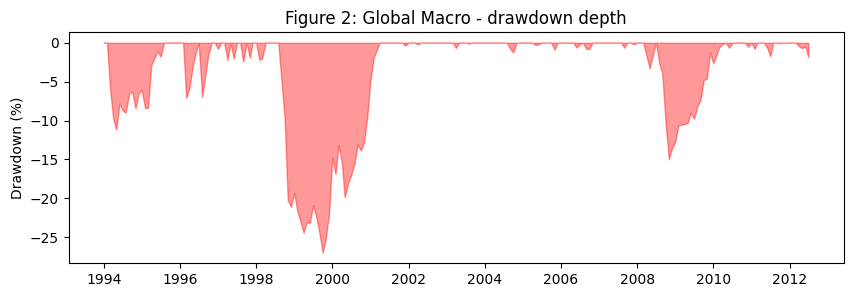

In [14]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(V_gm.index, V_gm, label="Cumulative wealth")
ax.plot(HWM_gm.index, HWM_gm, linestyle="--", linewidth=0.8, label="High-water mark")
ax.axvline(peak, color="green", linestyle=":", label="Peak")
ax.axvline(trough, color="red", linestyle=":", label="Trough")
if recovery is not None:
    ax.axvline(recovery, color="purple", linestyle=":", label="Recovery")
ax.set_title("Figure 1: Global Macro - cumulative wealth (start = 100)")
ax.set_ylabel("Wealth")
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(10, 3))
ax.fill_between(DD_gm.index, -DD_gm * 100, 0, color="red", alpha=0.4)
ax.set_title("Figure 2: Global Macro - drawdown depth")
ax.set_ylabel("Drawdown (%)")
plt.show()

### 9. Lag-one autocorrelation of monthly excess returns

In [15]:
E = df[strategies].sub(df["RF"], axis=0)           # monthly excess returns

ac1 = E.apply(lambda x: x.autocorr(lag=1))
ac1.index = short(ac1.index)
ac1 = ac1.sort_values(ascending=False)

print("Table 7: Lag-one autocorrelation of monthly excess returns")
print(ac1.round(4))
print("\nTop three:")
print(ac1.head(3).round(4))

Table 7: Lag-one autocorrelation of monthly excess returns
Cnvrt Arb     0.5552
Fx Inc Arb    0.5283
Evnt Drvn     0.3629
Emg Mkts      0.3055
Ln/Sh Eq      0.1919
Ded Sh Bs     0.0819
Global Mac    0.0744
Eq Mkt Ntr    0.0555
Mngd Fut      0.0263
dtype: float64

Top three:
Cnvrt Arb     0.5552
Fx Inc Arb    0.5283
Evnt Drvn     0.3629
dtype: float64


### 10. Sharpe ratio vs. volatility and tail-risk measures

In [16]:
table8 = table3[["Sharpe", "Vol", "Skew", "Ex. kurt", "MDD"]].sort_values("Sharpe", ascending=False)

print("Table 8: Sharpe ratio vs. volatility and tail-risk measures")
print(table8.round(4))

Table 8: Sharpe ratio vs. volatility and tail-risk measures
            Sharpe     Vol     Skew  Ex. kurt     MDD
Evnt Drvn   0.9200  0.0629  -2.2441   11.3846  0.1930
Global Mac  0.8783  0.0964  -0.0994    3.9010  0.2700
Cnvrt Arb   0.6246  0.0690  -2.5672   15.8173  0.3300
Ln/Sh Eq    0.6058  0.0990  -0.0731    3.2026  0.2214
Fx Inc Arb  0.3832  0.0573  -4.2300   29.3784  0.2910
Emg Mkts    0.3319  0.1489  -0.8086    5.1433  0.4533
Mngd Fut    0.2639  0.1169   0.0246   -0.0259  0.1788
Eq Mkt Ntr  0.2201  0.1022 -11.9943  165.3335  0.4513
Ded Sh Bs  -0.3362  0.1697   0.6527    1.3126  0.6424


## Part V: Factor attribution for Equity Long/Short
Dependent variable: Equity Long/Short monthly excess return X_t.
- One-factor: X_t = α + β_M (Mkt−RF)_t + ε_t
- Four-factor: X_t = α + β_M (Mkt−RF)_t + β_S SMB_t + β_V HML_t + β_U UMD_t + ε_t

### 11. Regression results (conventional OLS standard errors)

In [17]:
X = df["Ln/Sh Eq Hedge Fund USD"] - df["RF"]

one = sm.OLS(X, sm.add_constant(df[["Mkt-RF"]])).fit()
four = sm.OLS(X, sm.add_constant(df[["Mkt-RF", "SMB", "HML", "UMD"]])).fit()

print(one.summary())
print(four.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.571
Model:                            OLS   Adj. R-squared:                  0.569
Method:                 Least Squares   F-statistic:                     293.3
Date:                Fri, 09 Oct 2026   Prob (F-statistic):           2.37e-42
Time:                        15:28:39   Log-Likelihood:                 568.73
No. Observations:                 222   AIC:                            -1133.
Df Residuals:                     220   BIC:                            -1127.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0027      0.001      2.101      0.0

In [18]:
def reg_stats(m):
    a = m.params["const"]
    se = m.bse["const"]
    resid_vol_ann = np.sqrt(m.mse_resid) * np.sqrt(12)
    return {
        "Alpha (monthly)": a,
        "Alpha (ann.)": 12 * a,
        "t(alpha)": m.tvalues["const"],
        "p(alpha)": m.pvalues["const"],
        "95% CI alpha monthly - low": a - 1.96 * se,
        "95% CI alpha monthly - high": a + 1.96 * se,
        "95% CI alpha ann. - low": 12 * (a - 1.96 * se),
        "95% CI alpha ann. - high": 12 * (a + 1.96 * se),
        "beta_M (Mkt-RF)": m.params.get("Mkt-RF", np.nan),
        "beta_S (SMB)": m.params.get("SMB", np.nan),
        "beta_V (HML)": m.params.get("HML", np.nan),
        "beta_U (UMD)": m.params.get("UMD", np.nan),
        "Adj. R2": m.rsquared_adj,
        "Residual vol (ann.)": resid_vol_ann,
        "Appraisal ratio (ann.)": 12 * a / resid_vol_ann,
        "Residual autocorr (lag 1)": m.resid.autocorr(lag=1),
    }

table9 = pd.DataFrame({"One-factor": reg_stats(one), "Four-factor": reg_stats(four)})

print("Table 9: Equity Long/Short - one-factor and four-factor regressions (OLS standard errors)")
print(table9.round(4))

Table 9: Equity Long/Short - one-factor and four-factor regressions (OLS standard errors)
                             One-factor  Four-factor
Alpha (monthly)                  0.0027       0.0016
Alpha (ann.)                     0.0319       0.0193
t(alpha)                         2.1007       1.6856
p(alpha)                         0.0368       0.0933
95% CI alpha monthly - low       0.0002      -0.0003
95% CI alpha monthly - high      0.0051       0.0035
95% CI alpha ann. - low          0.0021      -0.0031
95% CI alpha ann. - high         0.0617       0.0417
beta_M (Mkt-RF)                  0.4597       0.4677
beta_S (SMB)                        NaN       0.1772
beta_V (HML)                        NaN      -0.0826
beta_U (UMD)                        NaN       0.1664
Adj. R2                          0.5695       0.7639
Residual vol (ann.)              0.0650       0.0481
Appraisal ratio (ann.)           0.4913       0.4007
Residual autocorr (lag 1)        0.1540       0.1769


### 12. Four-factor loadings: statistical significance

In [19]:
factors = ["Mkt-RF", "SMB", "HML", "UMD"]

table10_load = pd.DataFrame({
    "Loading": four.params[factors],
    "t-stat": four.tvalues[factors],
    "p-value": four.pvalues[factors],
})

print("Table 10: Four-factor loadings")
print(table10_load.round(4))

Table 10: Four-factor loadings
        Loading   t-stat  p-value
Mkt-RF   0.4677  21.1483   0.0000
SMB      0.1772   6.1498   0.0000
HML     -0.0826  -2.6970   0.0075
UMD      0.1664   9.0607   0.0000


### 13. Alpha comparison

In [20]:
alpha_one = 12 * one.params["const"]
alpha_four = 12 * four.params["const"]

print(f"Annualized alpha, one-factor:  {alpha_one:.4f}")
print(f"Annualized alpha, four-factor: {alpha_four:.4f}")
print(f"Reduction: {alpha_one - alpha_four:.4f} per year ({(alpha_one - alpha_four) / alpha_one:.1%} of the one-factor alpha)")
print(f"Adjusted R2: {one.rsquared_adj:.4f} -> {four.rsquared_adj:.4f}")

Annualized alpha, one-factor:  0.0319
Annualized alpha, four-factor: 0.0193
Reduction: 0.0126 per year (39.6% of the one-factor alpha)
Adjusted R2: 0.5695 -> 0.7639


## Part VI: Practitioner memo
### 14. Recap of the three strategies

In [21]:
recap = pd.concat([
    table3.loc[three],                              # returns, volatility, Sharpe, MDD, skew, kurtosis
    table4.loc[three],                              # active return, tracking error, information ratio
    ac1.loc[three].rename("Autocorr (lag 1)"),      # smoothing / stale-price signal
], axis=1)

print("Table 11: Recap - Equity Long/Short, Global Macro, Convertible Arbitrage")
print(recap.T.round(4))

Table 11: Recap - Equity Long/Short, Global Macro, Convertible Arbitrage
                   Ln/Sh Eq  Global Mac  Cnvrt Arb
Arith. ret           0.0904      0.1151     0.0735
Geo. ret             0.0889      0.1163     0.0734
Vol                  0.0990      0.0964     0.0690
Sharpe               0.6058      0.8783     0.6246
MDD                  0.2214      0.2700     0.3300
Skew                -0.0731     -0.0994    -2.5672
Ex. kurt             3.2026      3.9010    15.8173
Active return        0.0063      0.0310    -0.0106
Tracking error       0.0557      0.0569     0.0687
Information ratio    0.1130      0.5448    -0.1541
Autocorr (lag 1)     0.1919      0.0744     0.5552
